# RNN — classificação binária com scikit-learn

    Exemplo independente do estudo de dengue. Dataset: Breast Cancer Wisconsin Diagnostic,
    embarcado no scikit-learn. Mesmas amostras e partições para as três arquiteturas.
    Classe positiva: **maligno (1)**. Limiar fixo: **0,5**.

    Execute as células em ordem. A pasta `results` é atualizada a cada execução.
    Treino: 60%; validação: 20%; teste: 20%, com estratificação e semente 42.
    O teste só é avaliado depois da seleção do modelo na validação.
    Este é um exercício de programação e comparação de modelos.

## 1. Importação de bibliotecas

In [1]:
%matplotlib inline
from pathlib import Path
import copy
import json
import platform
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (f1_score, roc_auc_score, accuracy_score, recall_score,
                             roc_curve, confusion_matrix, classification_report)
import joblib

import torch
from torch import nn
from captum.attr import Saliency, IntegratedGradients

/home/lorenzo/.local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
SEED = 42
THRESHOLD = 0.5
MODEL_KEY = 'rnn'
MODEL_TITLE = 'RNN'
cwd = Path.cwd().resolve()
if cwd.name == MODEL_KEY and cwd.parent.name == 'models':
    MODEL_DIR = cwd
elif cwd.name == 'models':
    MODEL_DIR = cwd / MODEL_KEY
elif (cwd / 'models' / MODEL_KEY).is_dir():
    MODEL_DIR = cwd / 'models' / MODEL_KEY
else:
    raise RuntimeError('Abra o notebook na pasta do modelo, em models ou na raiz do projeto.')
RESULTS = MODEL_DIR / 'results'
DIRS = {name: RESULTS / name for name in
        ['data', 'metrics', 'figures', 'explainability', 'artifacts']}
for directory in DIRS.values():
    directory.mkdir(parents=True, exist_ok=True)
COLORS = {'treino': '#2563EB', 'validacao': '#D97706', 'teste': '#059669',
          'saliency': '#7C3AED', 'integrated_gradients': '#0891B2', 'shap': '#7C3AED'}
SPLIT_LABELS = {'treino': 'Treino', 'validacao': 'Validação', 'teste': 'Teste'}
METRIC_LABELS = {'f1': 'F1', 'roc_auc': 'ROC-AUC', 'accuracy': 'Acurácia', 'recall': 'Recall'}
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11,
    'axes.titlesize': 13, 'axes.labelsize': 11, 'figure.facecolor': 'white',
    'axes.facecolor': 'white', 'axes.grid': True, 'grid.alpha': 0.2,
    'axes.spines.top': False, 'axes.spines.right': False, 'savefig.dpi': 160})
np.random.seed(SEED)

def save_figure(fig, name):
    fig.tight_layout()
    for extension in ['png', 'svg']:
        fig.savefig(DIRS['figures'] / f'{name}.{extension}', bbox_inches='tight')
    plt.show()
    plt.close(fig)

def calculate_metrics(y_true, probability):
    prediction = (probability >= THRESHOLD).astype(int)
    return {'f1': f1_score(y_true, prediction, zero_division=0),
            'roc_auc': roc_auc_score(y_true, probability),
            'accuracy': accuracy_score(y_true, prediction),
            'recall': recall_score(y_true, prediction, zero_division=0)}

## 2. Importação do dataset para DataFrame pandas

In [3]:
# Dataset local ao scikit-learn: nenhum download ou dado do projeto de dengue.
dataset = load_breast_cancer(as_frame=True)
feature_names = dataset.feature_names.tolist()
df = dataset.data.copy()
# Classe positiva explícita: 1 = maligno, 0 = benigno.
df['target'] = (dataset.target == 0).astype(int)
df.index.name = 'sample_id'
df.to_csv(DIRS['data'] / 'dataset_original.csv', index=True)
display(df.head())
print(f'{len(df)} amostras; {len(feature_names)} atributos; classe positiva = maligno.')

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
sample_id,,,,,,,,,,,,,,,,,,,,,
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


569 amostras; 30 atributos; classe positiva = maligno.


## 3. Tratamento do DataFrame e divisão dos dados

              Verificamos ausências e valores não finitos; preservamos o identificador original.
              O dataset já está completo, portanto não é necessária imputação.
              A padronização usa somente o treino e é aplicada às três partições.
              Valores originais e unidades dos atributos estão descritos em `dataset_description.txt`.

In [4]:
assert df.index.is_unique
assert not df.isna().any().any(), 'O dataset de demonstração deve estar completo.'
assert np.isfinite(df.to_numpy()).all()
assert set(df.target.unique()) == {0, 1}

train_ids, remaining_ids = train_test_split(
    df.index.to_numpy(), test_size=0.4, stratify=df.target, random_state=SEED)
val_ids, test_ids = train_test_split(
    remaining_ids, test_size=0.5, stratify=df.loc[remaining_ids, 'target'], random_state=SEED)
split_ids = {'treino': train_ids, 'validacao': val_ids, 'teste': test_ids}
assert not (set(train_ids) & set(val_ids) or set(train_ids) & set(test_ids)
            or set(val_ids) & set(test_ids))
assert set(np.concatenate(list(split_ids.values()))) == set(df.index)

scaler = StandardScaler()
scaler.fit(df.loc[train_ids, feature_names])  # ajuste exclusivamente no treino
X = {name: scaler.transform(df.loc[ids, feature_names]).astype(np.float32)
     for name, ids in split_ids.items()}
y = {name: df.loc[ids, 'target'].to_numpy(dtype=np.int64)
     for name, ids in split_ids.items()}
partition_rows = []
for name, ids in split_ids.items():
    transformed = pd.DataFrame(X[name], columns=feature_names, index=ids)
    transformed.index.name = 'sample_id'
    transformed['target'] = y[name]
    transformed.to_csv(DIRS['data'] / f'{name}_padronizado.csv')
    partition_rows.extend({'sample_id': int(i), 'split': name, 'target': int(df.loc[i, 'target'])}
                          for i in ids)
partitions = pd.DataFrame(partition_rows)
partitions.to_csv(DIRS['data'] / 'particoes.csv', index=False)
summary = partitions.groupby('split').agg(amostras=('target', 'size'),
    positivos=('target', 'sum'), prevalencia=('target', 'mean')).reindex(split_ids)
summary.to_csv(DIRS['data'] / 'resumo_particoes.csv')
pd.DataFrame({'feature': feature_names, 'train_mean': scaler.mean_,
              'train_scale': scaler.scale_}).to_csv(DIRS['data'] / 'padronizacao.csv', index=False)
joblib.dump(scaler, DIRS['artifacts'] / 'scaler.joblib')
display(summary)

,amostras,positivos,prevalencia
split,,,
treino,341,127,0.372434
validacao,114,43,0.377193
teste,114,42,0.368421


## 3.1. Análise exploratória dos dados

As distribuições, estatísticas, histogramas, boxplots, ausências e correlações dos
atributos usam **somente o treino**. A composição das classes e sua impureza são
descritas nas três partições. Todos os 30 atributos são mantidos; esta seção não
seleciona atributos nem altera o treinamento.

Para comparar medidas de diferentes escalas, histogramas e boxplots usam valores
padronizados, em desvios padrão (DP) da média do treino. As estatísticas originais
também são exportadas. O boxplot usa quartis e limites de 1,5 IQR; pontos além
desses limites são exibidos, sem remoção de amostras.

**Gini das classes:** `1 − soma(p_classe²)`, de 0 a 0,5 no caso binário. Mede a
mistura das classes, não desigualdade de renda nem desempenho do modelo.


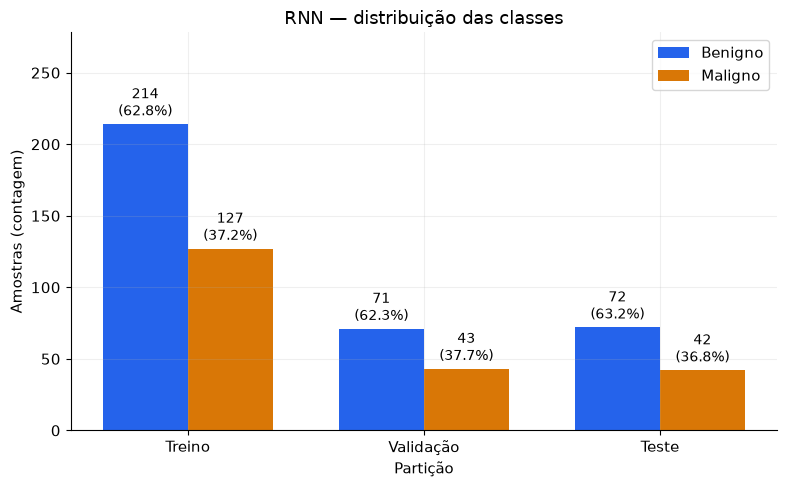

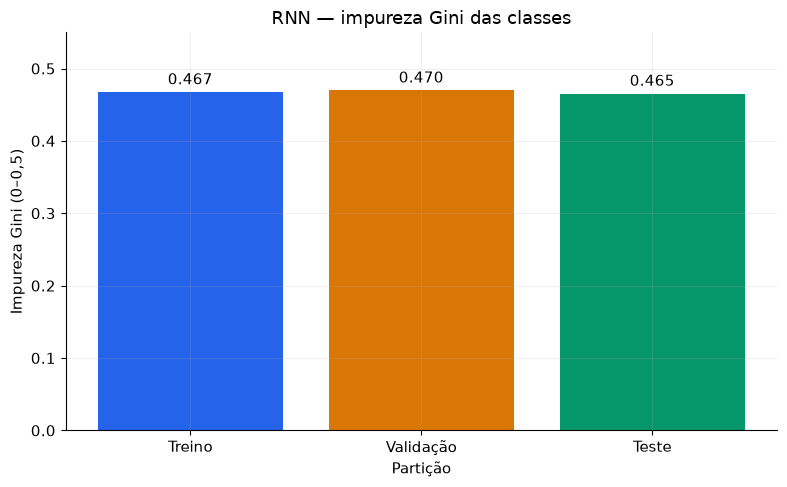

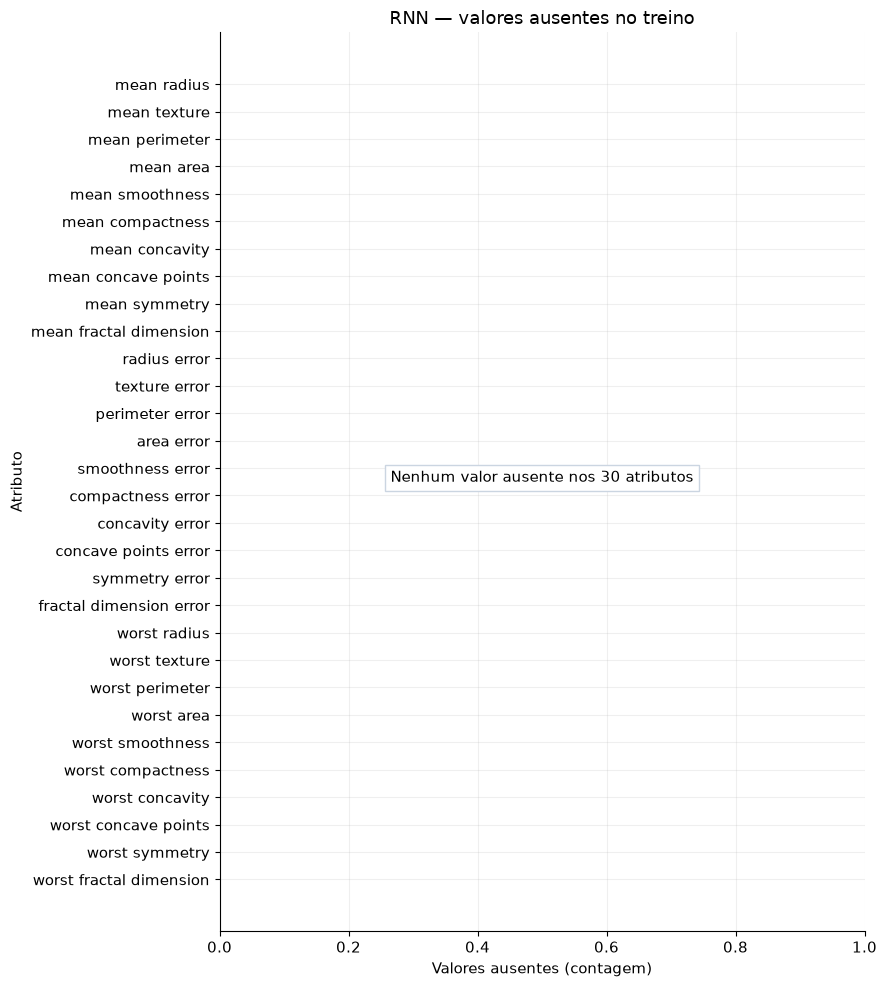

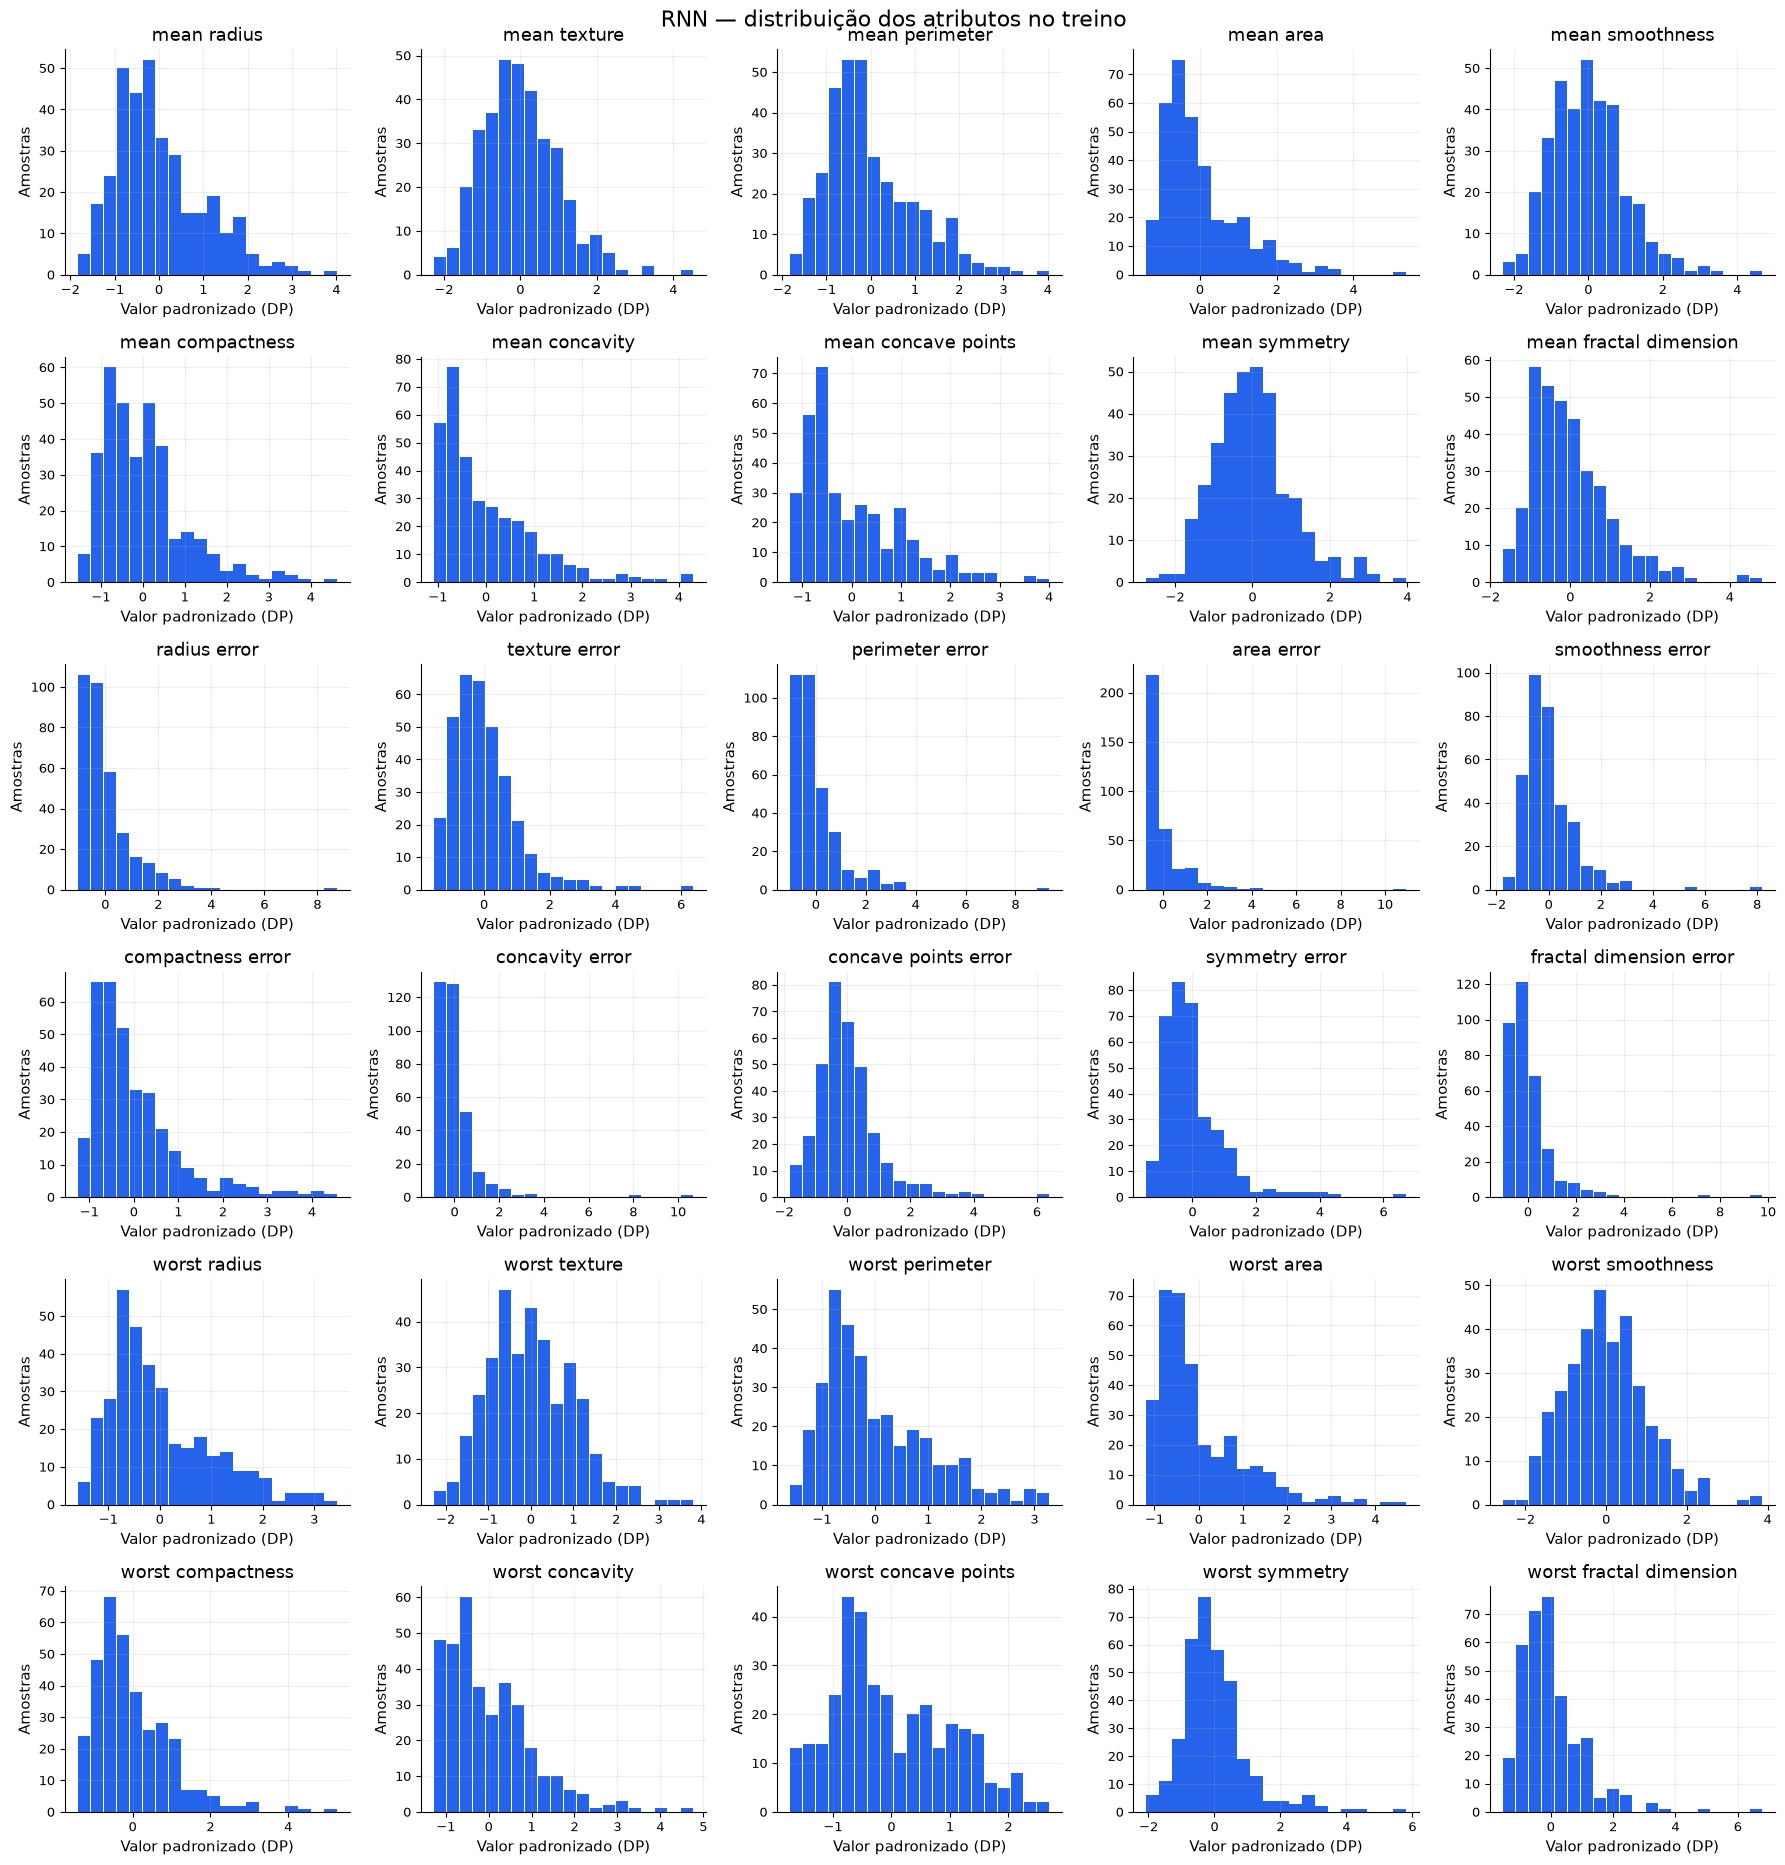

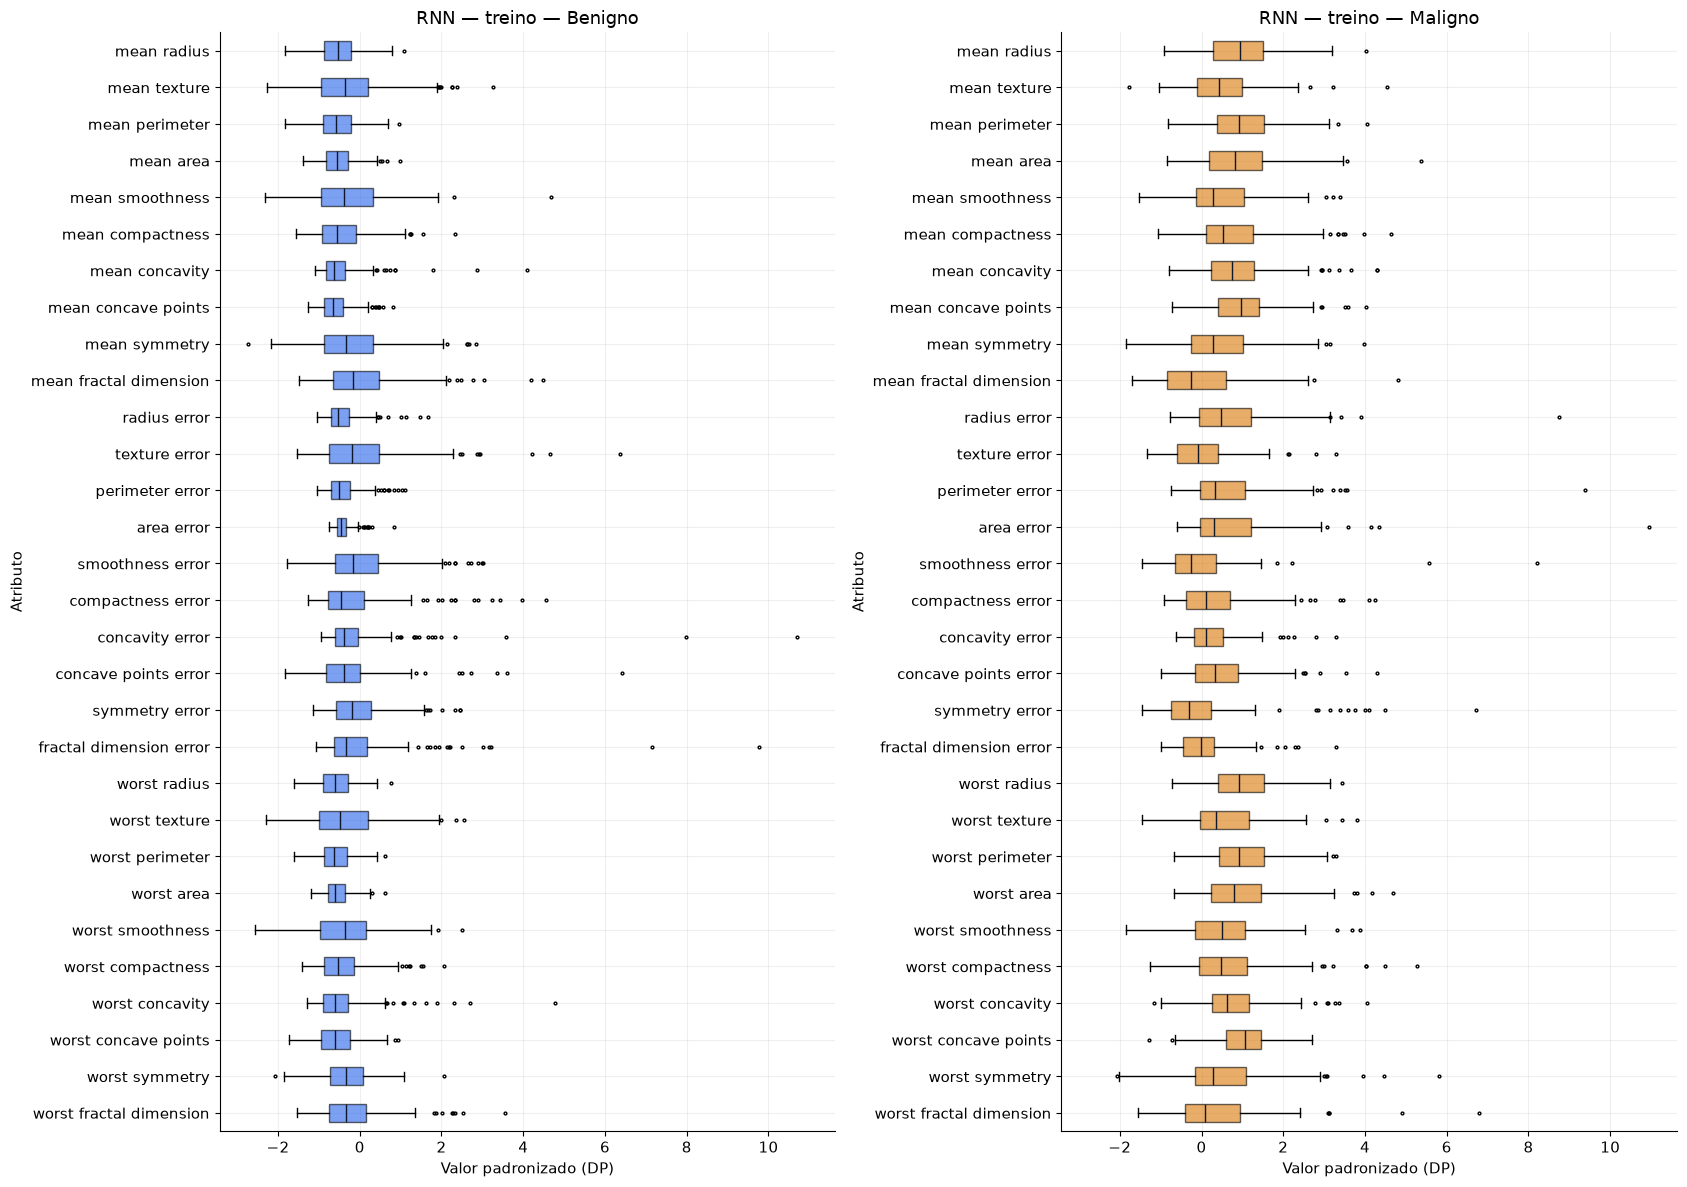

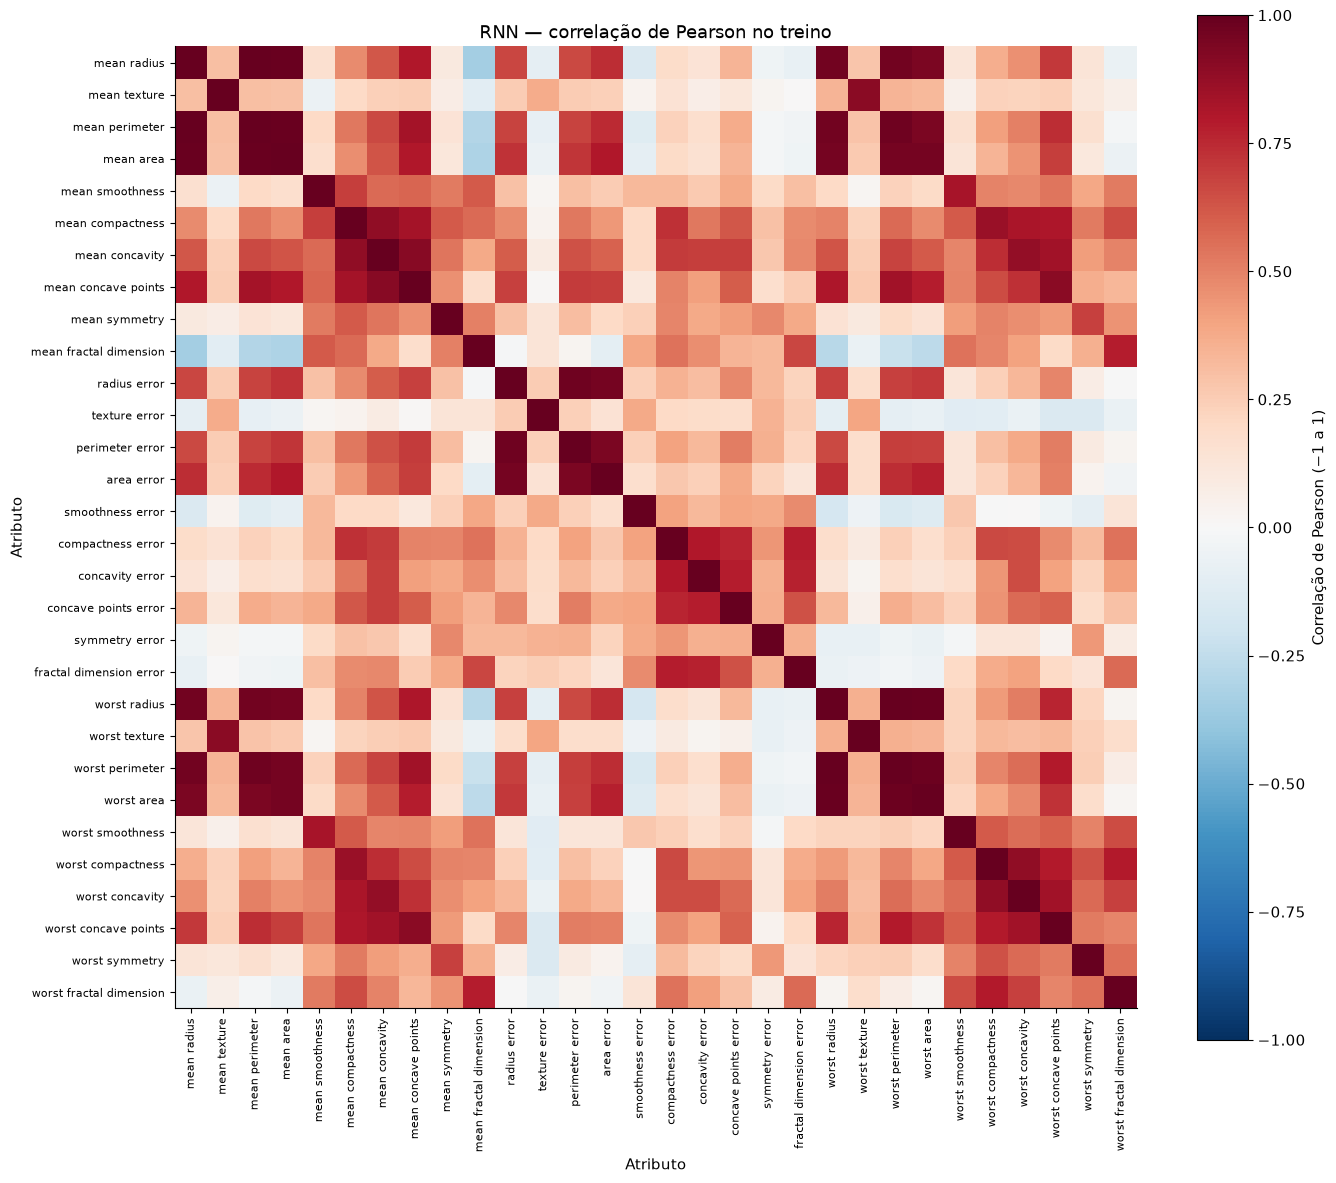

,split,n_samples,gini_impurity
0,treino,341,0.467454
1,validacao,114,0.469837
2,teste,114,0.465374


,count,mean,std,min,25%,50%,75%,max
mean radius,341.0,14.107827,3.490660,7.69100,11.60000,13.27000,16.0300,28.1100
mean texture,341.0,19.583636,4.355908,9.71000,16.49000,19.07000,22.0400,39.2800
mean perimeter,341.0,91.724311,23.960088,47.98000,74.65000,86.18000,105.1000,188.5000
mean area,341.0,652.242522,344.612598,170.40000,409.00000,545.20000,798.8000,2499.0000
mean smoothness,341.0,0.095864,0.014470,0.06251,0.08481,0.09495,0.1044,0.1634


In [5]:
# Exploração dos atributos exclusivamente no treino.
from matplotlib.cbook import boxplot_stats

COLORS.update({'benigno': '#2563EB', 'maligno': '#D97706',
               'dados': '#2563EB', 'gini': '#7C3AED'})
CLASS_LABELS = {0: 'Benigno', 1: 'Maligno'}
eda_dir = RESULTS / 'eda'
eda_dir.mkdir(parents=True, exist_ok=True)
train_raw = df.loc[train_ids, feature_names]
train_scaled = pd.DataFrame(X['treino'], columns=feature_names, index=train_ids)
train_scaled.index.name = 'sample_id'

# 1. Composição das partições; somente contagens de rótulos fora do treino.
class_rows, gini_rows = [], []
for split in split_ids:
    n = len(y[split])
    counts = np.bincount(y[split], minlength=2)
    proportions = counts / n
    gini_rows.append({'split': split, 'n_samples': n,
                      'gini_impurity': float(1 - np.sum(proportions ** 2))})
    class_rows.extend({'split': split, 'class_id': cls, 'class_label': CLASS_LABELS[cls],
                       'count': int(counts[cls]), 'proportion': float(proportions[cls])}
                      for cls in [0, 1])
class_distribution = pd.DataFrame(class_rows)
gini_distribution = pd.DataFrame(gini_rows)
class_distribution.to_csv(eda_dir / 'distribuicao_classes.csv', index=False)
gini_distribution.to_csv(eda_dir / 'gini_classes.csv', index=False)
fig, ax = plt.subplots(figsize=(8, 5))
positions = np.arange(3)
for cls, offset, key in [(0, -0.18, 'benigno'), (1, 0.18, 'maligno')]:
    rows = class_distribution[class_distribution.class_id == cls]
    bars = ax.bar(positions + offset, rows['count'], width=0.36,
                  color=COLORS[key], label=CLASS_LABELS[cls])
    ax.bar_label(bars, labels=[f'{count}\n({proportion:.1%})'
                              for count, proportion in zip(rows['count'], rows.proportion)],
                 padding=3, fontsize=10)
ax.set(xticks=positions, xticklabels=list(SPLIT_LABELS.values()),
       title=f'{MODEL_TITLE} — distribuição das classes',
       xlabel='Partição', ylabel='Amostras (contagem)')
ax.set_ylim(0, class_distribution['count'].max() * 1.3)
ax.legend()
save_figure(fig, '00_eda_distribuicao_classes')

# Impureza do alvo binário: 0 = uma única classe; 0,5 = classes equilibradas.
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar([SPLIT_LABELS[s] for s in gini_distribution.split],
              gini_distribution.gini_impurity,
              color=[COLORS[s] for s in gini_distribution.split])
ax.bar_label(bars, fmt='%.3f', padding=3)
ax.set(title=f'{MODEL_TITLE} — impureza Gini das classes', xlabel='Partição',
       ylabel='Impureza Gini (0–0,5)', ylim=(0, 0.55))
save_figure(fig, '00_eda_gini_classes')

# 2. Estatísticas e qualidade dos atributos: nenhum dado de validação/teste.
train_raw.describe().T.rename_axis('feature').to_csv(eda_dir / 'estatisticas_originais_treino.csv')
train_scaled.describe().T.rename_axis('feature').to_csv(eda_dir / 'estatisticas_padronizadas_treino.csv')
missing = pd.DataFrame({'feature': feature_names,
    'missing_count': train_raw.isna().sum().to_numpy(),
    'missing_proportion': train_raw.isna().mean().to_numpy()})
missing.to_csv(eda_dir / 'valores_ausentes_treino.csv', index=False)
fig, ax = plt.subplots(figsize=(9, 10))
ax.barh(missing.feature.iloc[::-1], missing.missing_count.iloc[::-1], color=COLORS['dados'])
ax.set(title=f'{MODEL_TITLE} — valores ausentes no treino',
       xlabel='Valores ausentes (contagem)', ylabel='Atributo', xlim=(0, max(1, missing.missing_count.max() * 1.1)))
if missing.missing_count.sum() == 0:
    ax.text(0.5, 0.5, 'Nenhum valor ausente nos 30 atributos', transform=ax.transAxes,
            ha='center', bbox={'facecolor': 'white', 'edgecolor': '#CBD5E1'})
save_figure(fig, '00_eda_valores_ausentes')

# 3. Histogramas: todos os atributos, com 20 intervalos e escala padronizada.
histogram_rows = []
fig, axes = plt.subplots(6, 5, figsize=(18, 19))
for ax, feature in zip(axes.flat, feature_names):
    counts, edges = np.histogram(train_scaled[feature], bins=20)
    widths = np.diff(edges)
    centers = (edges[:-1] + edges[1:]) / 2
    ax.bar(centers, counts, width=widths * 0.95, color=COLORS['dados'])
    ax.set(title=feature, xlabel='Valor padronizado (DP)', ylabel='Amostras')
    ax.tick_params(labelsize=9)
    histogram_rows.extend({'feature': feature, 'bin_left': float(left),
        'bin_right': float(right), 'bin_center': float(center), 'bin_width': float(width),
        'count': int(count)} for left, right, center, width, count in
        zip(edges[:-1], edges[1:], centers, widths, counts))
fig.suptitle(f'{MODEL_TITLE} — distribuição dos atributos no treino', fontsize=16)
pd.DataFrame(histogram_rows).to_csv(eda_dir / 'histogramas_treino.csv', index=False)
save_figure(fig, '00_eda_histogramas_treino')

# 4. Boxplots por classe, quartis, limites de 1,5 IQR e outliers exportados.
box_rows, outlier_rows = [], []
fig, axes = plt.subplots(1, 2, figsize=(17, 12), sharex=True)
for ax, cls, key in zip(axes, [0, 1], ['benigno', 'maligno']):
    stats = []
    for feature in feature_names:
        values = train_scaled.loc[y['treino'] == cls, feature]
        stat = boxplot_stats(values.to_numpy(), whis=1.5)[0]
        stat['label'] = feature
        stats.append(stat)
        box_rows.append({'feature': feature, 'class_id': cls, 'class_label': CLASS_LABELS[cls],
            'n_samples': len(values), **{k: float(stat[k]) for k in ['mean', 'med', 'q1', 'q3', 'whislo', 'whishi']}})
        outlier_rows.extend({'feature': feature, 'class_id': cls, 'value': float(v)} for v in stat['fliers'])
    artists = ax.bxp(stats, orientation='horizontal', patch_artist=True,
                     medianprops={'color': '#0F172A'}, flierprops={'markersize': 2})
    for box in artists['boxes']:
        box.set_facecolor(COLORS[key])
        box.set_alpha(0.6)
    ax.invert_yaxis()
    ax.set(title=f'{MODEL_TITLE} — treino — {CLASS_LABELS[cls]}',
           xlabel='Valor padronizado (DP)', ylabel='Atributo')
pd.DataFrame(box_rows).to_csv(eda_dir / 'boxplots_treino.csv', index=False)
pd.DataFrame(outlier_rows, columns=['feature', 'class_id', 'value']).to_csv(
    eda_dir / 'boxplots_outliers_treino.csv', index=False)
save_figure(fig, '00_eda_boxplots_treino')

# 5. Correlação de Pearson entre atributos; não implica causalidade.
correlations = train_scaled.corr(method='pearson')
correlation_rows = [{'feature_x': col, 'feature_y': row, 'correlation': float(correlations.loc[row, col])}
                    for row in feature_names for col in feature_names]
pd.DataFrame(correlation_rows).to_csv(eda_dir / 'correlacoes_treino.csv', index=False)
fig, ax = plt.subplots(figsize=(14, 12))
im = ax.imshow(correlations.to_numpy(), cmap='RdBu_r', vmin=-1, vmax=1)
ax.set(xticks=np.arange(len(feature_names)), yticks=np.arange(len(feature_names)),
       xticklabels=feature_names, yticklabels=feature_names,
       title=f'{MODEL_TITLE} — correlação de Pearson no treino',
       xlabel='Atributo', ylabel='Atributo')
ax.tick_params(axis='x', rotation=90, labelsize=8)
ax.tick_params(axis='y', labelsize=8)
ax.grid(False)
fig.colorbar(im, ax=ax, label='Correlação de Pearson (−1 a 1)')
save_figure(fig, '00_eda_correlacoes_treino')
display(gini_distribution)
display(train_raw.describe().T.head())


## 4. Arquitetura básica do modelo

Os dados são tabulares, sem eixo de tempo. Cada entrada tem formato
        `(amostras, 1 passo, 30 atributos)`. A camada recorrente é real e treinada por
        backpropagation, mas um único passo não permite estudar memória temporal.
        Para séries temporais reais, será preciso criar janelas e usar partições cronológicas.

In [6]:
torch.manual_seed(SEED)
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
DEVICE = torch.device('cpu')
MAX_EPOCHS = 150
PATIENCE = 20
LEARNING_RATE = 0.003
HIDDEN_SIZE = 24

class SequenceClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.recurrent = nn.RNN(input_size=len(feature_names), hidden_size=HIDDEN_SIZE,
                                   num_layers=1, batch_first=True)
        self.output = nn.Linear(HIDDEN_SIZE, 1)

    def forward(self, inputs):
        sequence_output, _ = self.recurrent(inputs)
        return self.output(sequence_output[:, -1, :]).squeeze(-1)

# Uma amostra tabular = um passo com 30 atributos; amostras nunca são concatenadas.
tensors = {split: torch.tensor(values[:, None, :], device=DEVICE) for split, values in X.items()}
targets = {split: torch.tensor(values, dtype=torch.float32, device=DEVICE) for split, values in y.items()}
model = SequenceClassifier().to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
criterion = nn.BCEWithLogitsLoss()
print(model)
print('Formato de entrada (amostras, passos, atributos):', tuple(tensors['treino'].shape))

SequenceClassifier(
  (recurrent): RNN(30, 24, batch_first=True)
  (output): Linear(in_features=24, out_features=1, bias=True)
)
Formato de entrada (amostras, passos, atributos): (341, 1, 30)


## 5. Treinamento e seleção pela validação

    Selecionamos o maior F1 de validação; em empate, preservamos o primeiro modelo.
    As curvas mostram somente treino e validação. O teste não escolhe a configuração.

In [7]:
history_rows = []
best_score = -np.inf
best_state = None
epochs_without_improvement = 0
for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    optimizer.zero_grad()
    loss = criterion(model(tensors['treino']), targets['treino'])
    loss.backward()
    nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
    optimizer.step()
    model.eval()
    with torch.no_grad():
        for split in ['treino', 'validacao']:
            logits = model(tensors[split])
            prob = torch.sigmoid(logits).cpu().numpy()
            scores = calculate_metrics(y[split], prob)
            history_rows.append({'step': epoch, 'split': split,
                'loss': criterion(logits, targets[split]).item(), **scores})
            if split == 'validacao':
                val_f1 = scores['f1']
    if val_f1 > best_score + 1e-8:
        best_score = val_f1
        selected_step = epoch
        best_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1
    if epochs_without_improvement >= PATIENCE:
        break
model.load_state_dict(best_state)
model.eval()
history = pd.DataFrame(history_rows)
history.to_csv(DIRS['metrics'] / 'historico_treinamento.csv', index=False)
torch.save({'state_dict': model.state_dict(), 'model_type': MODEL_KEY,
            'input_size': len(feature_names), 'hidden_size': HIDDEN_SIZE,
            'sequence_length': 1, 'feature_names': feature_names}, DIRS['artifacts'] / 'model.pt')
print(f'Época selecionada: {selected_step}; F1 validação = {best_score:.3f}')

Época selecionada: 70; F1 validação = 0.976


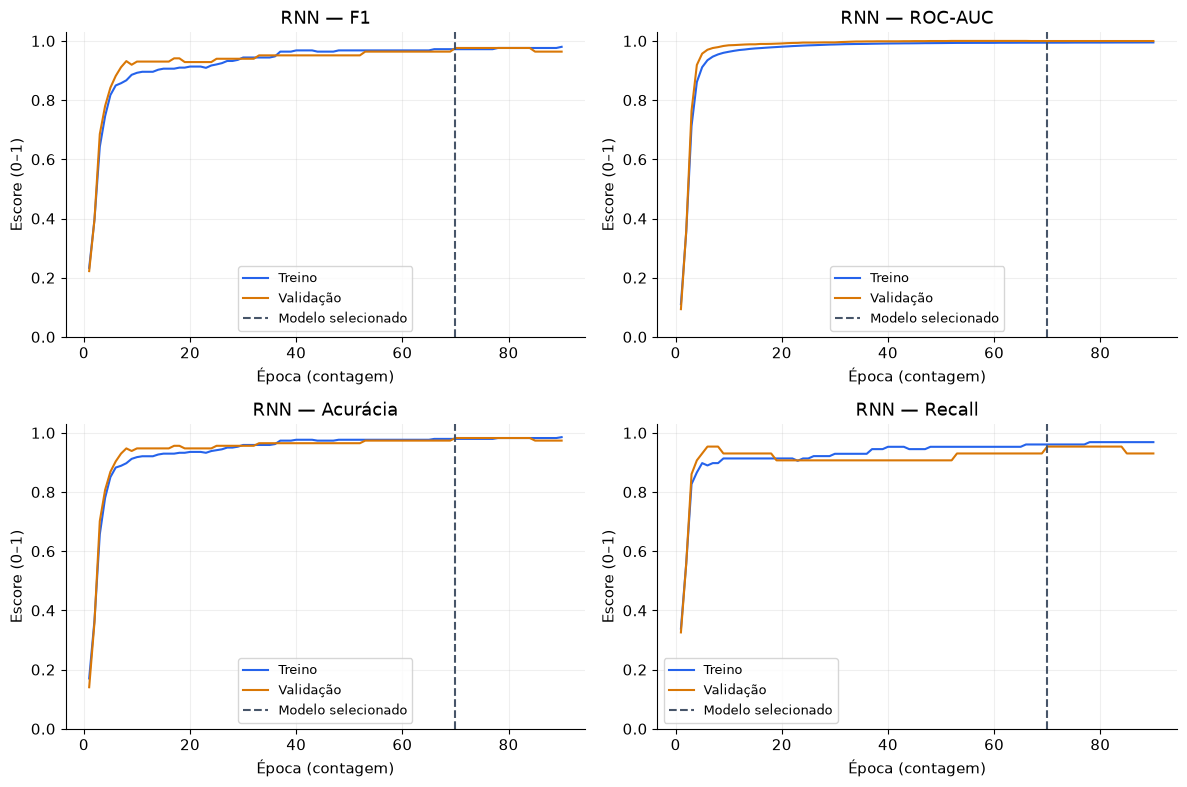

In [8]:
STEP_LABEL = "Época (contagem)"

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (metric, label) in zip(axes.flat, METRIC_LABELS.items()):
    for split in ['treino', 'validacao']:
        subset = history[history.split == split]
        ax.plot(subset.step, subset[metric], color=COLORS[split], label=SPLIT_LABELS[split])
    ax.axvline(selected_step, color='#475569', linestyle='--', label='Modelo selecionado')
    ax.set(title=f'{MODEL_TITLE} — {label}', xlabel=STEP_LABEL, ylabel='Escore (0–1)', ylim=(0, 1.03))
    ax.legend(fontsize=9)
save_figure(fig, '01_historico_metricas')

## 6. Validação e teste do modelo selecionado

        F1, ROC-AUC, acurácia e recall são escores entre 0 e 1. F1 e recall referem-se
        à classe positiva (maligno). ROC-AUC usa probabilidades; as outras métricas usam
        o limiar fixo 0,5. Comparar o mesmo teste não equivale a validação independente.

,f1,roc_auc,accuracy,recall
split,,,,
treino,0.9721,0.9941,0.9795,0.9606
validacao,0.9762,0.9997,0.9825,0.9535
teste,0.9630,0.9967,0.9737,0.9286


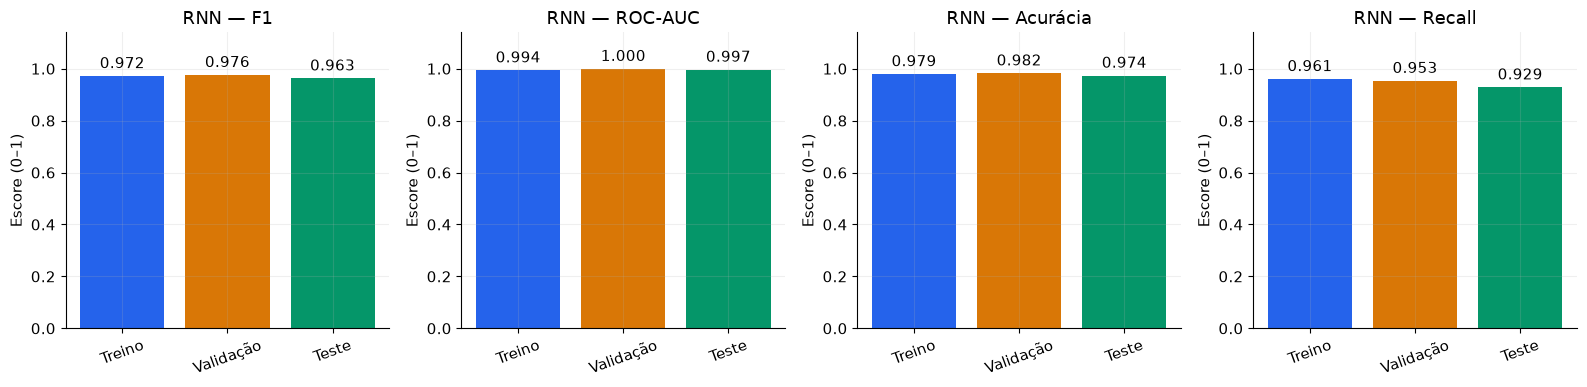

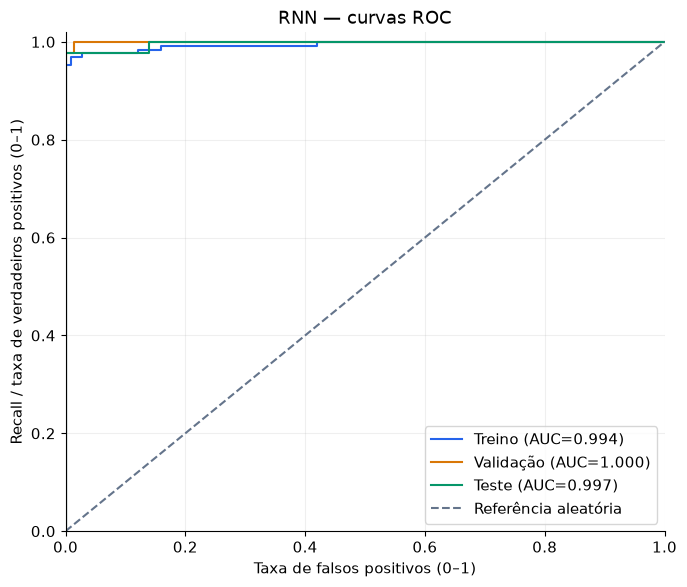

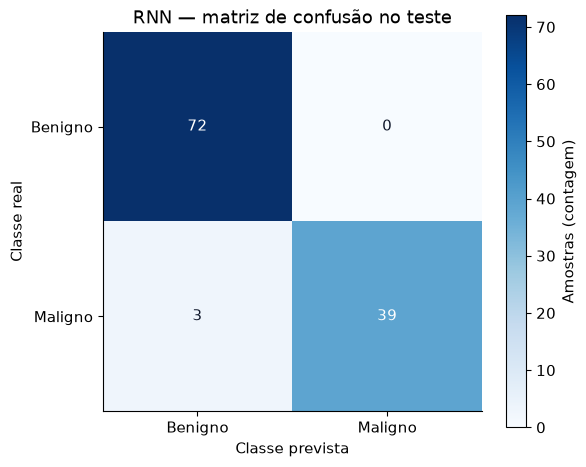

In [9]:
# Avaliação final: nenhuma decisão de seleção é tomada usando o teste.
probabilities = {}
for split in split_ids:
    with torch.no_grad():
        probabilities[split] = torch.sigmoid(model(tensors[split])).cpu().numpy()
metric_rows = []
roc_rows = []
reports = {}
for split, prob in probabilities.items():
    assert len(prob) == len(y[split]) and np.isfinite(prob).all()
    metric_rows.append({'split': split, **calculate_metrics(y[split], prob)})
    prediction = (prob >= THRESHOLD).astype(int)
    pd.DataFrame({'sample_id': split_ids[split], 'target': y[split],
        'probability_positive': prob, 'prediction': prediction}).to_csv(
            DIRS['data'] / f'previsoes_{split}.csv', index=False)
    fpr, tpr, thresholds = roc_curve(y[split], prob)
    roc_rows.extend({'split': split, 'false_positive_rate': float(a),
        'true_positive_rate': float(b), 'threshold': float(c) if np.isfinite(c) else None}
        for a, b, c in zip(fpr, tpr, thresholds))
    pd.DataFrame(confusion_matrix(y[split], prediction, labels=[0, 1]),
        index=['real_benigno', 'real_maligno'], columns=['previsto_benigno', 'previsto_maligno']).to_csv(
            DIRS['metrics'] / f'matriz_confusao_{split}.csv')
    reports[split] = classification_report(y[split], prediction, labels=[0, 1],
        target_names=['benigno', 'maligno'], output_dict=True, zero_division=0)
metrics = pd.DataFrame(metric_rows).set_index('split')
metrics.to_csv(DIRS['metrics'] / 'metricas_finais.csv')
pd.DataFrame(roc_rows).to_csv(DIRS['metrics'] / 'curvas_roc.csv', index=False)
(DIRS['metrics'] / 'relatorios_classificacao.json').write_text(
    json.dumps(reports, indent=2, ensure_ascii=False, allow_nan=False), encoding='utf-8')
display(metrics.round(4))

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (metric, label) in zip(axes, METRIC_LABELS.items()):
    bars = ax.bar([SPLIT_LABELS[s] for s in metrics.index], metrics[metric],
                  color=[COLORS[s] for s in metrics.index])
    ax.set(title=f'{MODEL_TITLE} — {label}', ylabel='Escore (0–1)', ylim=(0, 1.14))
    ax.tick_params(axis='x', rotation=20)
    ax.bar_label(bars, fmt='%.3f', padding=3)
save_figure(fig, '02_metricas_finais')

fig, ax = plt.subplots(figsize=(7, 6))
for split, prob in probabilities.items():
    fpr, tpr, _ = roc_curve(y[split], prob)
    ax.plot(fpr, tpr, color=COLORS[split],
            label=f'{SPLIT_LABELS[split]} (AUC={metrics.loc[split, "roc_auc"]:.3f})')
ax.plot([0, 1], [0, 1], '--', color='#64748B', label='Referência aleatória')
ax.set(title=f'{MODEL_TITLE} — curvas ROC', xlabel='Taxa de falsos positivos (0–1)',
       ylabel='Recall / taxa de verdadeiros positivos (0–1)', xlim=(0, 1), ylim=(0, 1.02))
ax.legend()
save_figure(fig, '03_curvas_roc')

cm = confusion_matrix(y['teste'], (probabilities['teste'] >= THRESHOLD).astype(int), labels=[0, 1])
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap='Blues')
for (i, j), value in np.ndenumerate(cm):
    ax.text(j, i, str(value), ha='center', va='center', color='white' if value > cm.max()/2 else '#0F172A')
ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=['Benigno', 'Maligno'],
       yticklabels=['Benigno', 'Maligno'], xlabel='Classe prevista', ylabel='Classe real',
       title=f'{MODEL_TITLE} — matriz de confusão no teste')
ax.grid(False)
fig.colorbar(im, ax=ax, label='Amostras (contagem)')
save_figure(fig, '04_matriz_confusao_teste')

## 7. Explicabilidade: Captum — Saliency e Integrated Gradients

In [10]:
def export_attributions(values, method, units):
    assert values.shape == X['teste'].shape
    assert np.isfinite(values).all()
    local = pd.DataFrame(values, columns=feature_names, index=test_ids)
    local.index.name = 'sample_id'
    local.to_csv(DIRS['explainability'] / f'{method}_atribuicoes.csv')
    importance = pd.DataFrame({'feature': feature_names,
        'mean_absolute_attribution': np.abs(values).mean(axis=0),
        'mean_signed_attribution': values.mean(axis=0)}).sort_values(
            'mean_absolute_attribution', ascending=False)
    importance.to_csv(DIRS['explainability'] / f'{method}_importancia.csv', index=False)
    top = importance.head(15).iloc[::-1]
    fig, ax = plt.subplots(figsize=(10, 7))
    ax.barh(top.feature, top.mean_absolute_attribution, color=COLORS[method])
    ax.set(title=f'{MODEL_TITLE} — {method.replace("_", " ").title()} — teste',
           xlabel=f'Média da atribuição absoluta ({units})', ylabel='Atributo padronizado')
    save_figure(fig, f'05_{method}_importancia')
    display(importance.head(10))
    return importance

/media/lorenzo/SSD/Projetos/ML-Dengue/.venv/lib/python3.12/site-packages/captum/attr/_utils/batching.py:51: UserWarning: Internal batch size cannot be less than the number of input examples. Defaulting to internal batch size of 114 equal to the number of examples.
  warnings.warn(


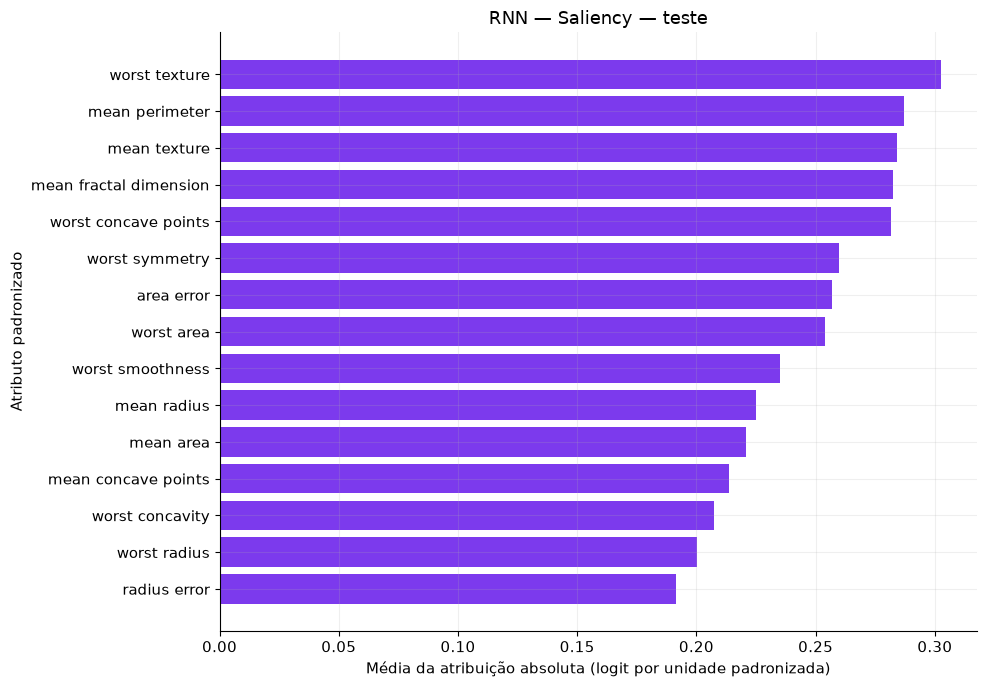

,feature,mean_absolute_attribution,mean_signed_attribution
21,worst texture,0.302549,0.302549
2,mean perimeter,0.286943,0.286891
1,mean texture,0.284010,0.284010
9,mean fractal dimension,0.282489,-0.282388
27,worst concave points,0.281633,0.281590
28,worst symmetry,0.259612,0.259503
13,area error,0.256934,0.256934
23,worst area,0.254115,0.254115
24,worst smoothness,0.235055,0.235055
0,mean radius,0.225143,0.225143


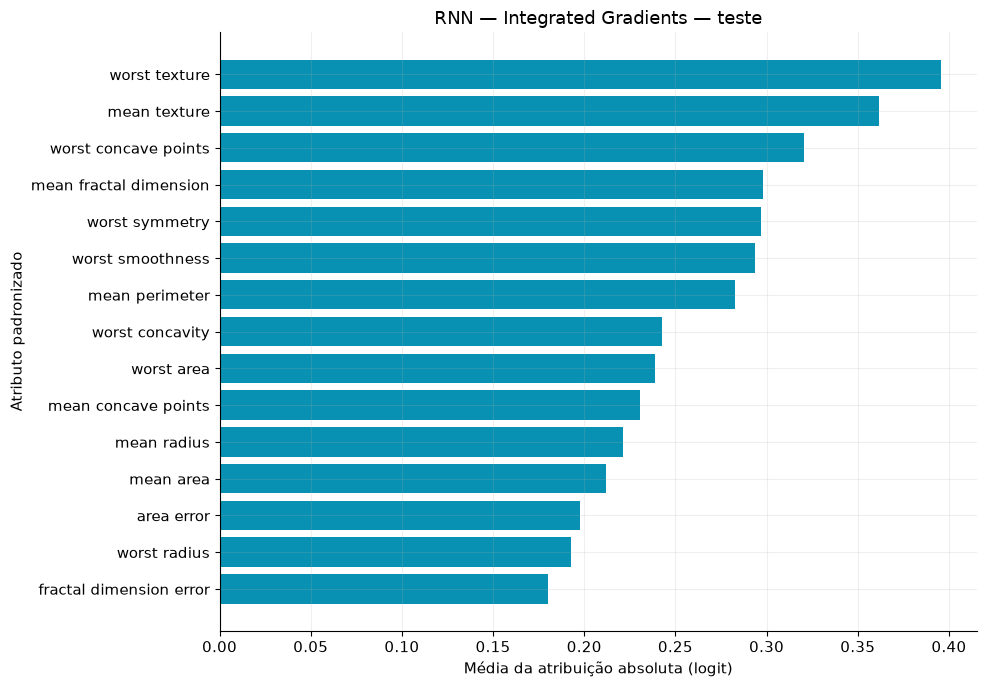

,feature,mean_absolute_attribution,mean_signed_attribution
21,worst texture,0.395604,-0.016639
1,mean texture,0.361887,-0.026373
27,worst concave points,0.320344,0.048086
9,mean fractal dimension,0.298124,-0.050978
28,worst symmetry,0.296664,0.043333
24,worst smoothness,0.293385,0.072250
2,mean perimeter,0.282847,0.001795
26,worst concavity,0.242908,0.047475
23,worst area,0.238974,-0.026231
7,mean concave points,0.230329,0.006131


Maior erro absoluto de completude IG: 1.1920929e-06


In [11]:
# A saída explicada é o logit de malignidade; zero padronizado = média do treino.
model.eval()
inputs = tensors['teste'].detach().clone().requires_grad_(True)
baseline = torch.zeros_like(inputs)
saliency = Saliency(model).attribute(inputs, abs=False).detach().cpu().numpy()[:, 0, :]
ig_values, delta = IntegratedGradients(model).attribute(
    inputs, baselines=baseline, n_steps=128, internal_batch_size=32,
    return_convergence_delta=True)
integrated_gradients = ig_values.detach().cpu().numpy()[:, 0, :]
export_attributions(saliency, 'saliency', 'logit por unidade padronizada')
export_attributions(integrated_gradients, 'integrated_gradients', 'logit')
with torch.no_grad():
    baseline_logit = model(baseline).cpu().numpy()
    predicted_logit = model(inputs).cpu().numpy()
completeness = pd.DataFrame({'sample_id': test_ids, 'baseline_logit': baseline_logit,
    'predicted_logit': predicted_logit, 'sum_attributions': integrated_gradients.sum(axis=1),
    'convergence_delta': delta.detach().cpu().numpy()})
completeness.to_csv(DIRS['explainability'] / 'integrated_gradients_convergencia.csv', index=False)
assert np.isfinite(completeness.to_numpy()).all()
assert np.abs(completeness.convergence_delta).max() < 0.01
print('Maior erro absoluto de completude IG:', np.abs(completeness.convergence_delta).max())

## 8. Exportação e rastreabilidade

              `data`: dataset, partições, padronização e previsões por amostra.
              `metrics`: histórico, métricas finais, ROC, matrizes de confusão e relatórios.
              `figures`: gráficos com títulos, cores e fonte comuns, em PNG e SVG.
              `explainability`: atribuições individuais, importância global e checagens numéricas.
              `artifacts`: modelo selecionado e scaler. `metadata.json`: configuração e unidades.
              `manifest.csv`: inventário de arquivos exportados.

In [12]:
packages = ['numpy', 'pandas', 'scikit-learn', 'matplotlib', 'joblib'] + ['torch', 'captum']
versions = {package: importlib.metadata.version(package) for package in packages}
metadata = {'model': MODEL_KEY, 'dataset': 'sklearn.datasets.load_breast_cancer',
    'seed': SEED, 'positive_class': 'maligno', 'target_mapping': {'benigno': 0, 'maligno': 1},
    'split': {'train': 0.6, 'validation': 0.2, 'test': 0.2},
    'split_stratified': True, 'threshold': THRESHOLD, 'selection_metric': 'validation_f1',
    'selected_step': int(selected_step), 'features': feature_names,
    'preprocessing': 'StandardScaler ajustado somente no treino',
    'sequence_length': None if MODEL_KEY == 'random_forest' else 1,
    'units': {'gini_class_impurity': '0–0,5 (binário)', 'gini_importance': 'importância normalizada (0–1)', 'eda_features': 'desvios padrão da média do treino', 'units_note': 'Estatísticas originais: unidades do dataset_description.txt', 'metrics': 'escore adimensional (0–1)', 'probabilities': '0–1',
              'processed_features': 'desvios padrão em relação à média do treino',
              'confusion_matrix': 'amostras',
              'shap': 'probabilidade da classe positiva (0–1)',
              'saliency': 'logit por unidade de entrada padronizada',
              'integrated_gradients': 'logit'},
    'colors': COLORS, 'font': 'DejaVu Sans', 'python': platform.python_version(),
    'versions': versions, 'test_used_for_selection': False,
    'limitations': ['Demonstração educacional com uma única divisão e uma semente.',
                   'RNN/LSTM com um passo não avaliam dependências temporais.',
                   'Explicações descrevem o modelo, não causalidade ou decisão clínica.']}
(RESULTS / 'metadata.json').write_text(json.dumps(metadata, indent=2, ensure_ascii=False,
                                                allow_nan=False), encoding='utf-8')
(DIRS['data'] / 'dataset_description.txt').write_text(dataset.DESCR, encoding='utf-8')
files = [{'path': str(p.relative_to(RESULTS)), 'bytes': p.stat().st_size}
         for p in sorted(RESULTS.rglob('*')) if p.is_file() and p.name != 'manifest.csv']
pd.DataFrame(files).to_csv(RESULTS / 'manifest.csv', index=False)
print(f'Exportação concluída: {RESULTS}')
display(pd.DataFrame(files))

Exportação concluída: /media/lorenzo/SSD/Projetos/ML-Dengue/models/rnn/results


,path,bytes
0,app_resultados.json,540459
1,artifacts/model.pt,9085
2,artifacts/scaler.joblib,2103
3,data/dataset_description.txt,4794
4,data/dataset_original.csv,123561
...,...,...
76,metrics/matriz_confusao_teste.csv,71
77,metrics/matriz_confusao_treino.csv,73
78,metrics/matriz_confusao_validacao.csv,71
79,metrics/metricas_finais.csv,284


## 9. Exportação JSON para gráficos e aplicativos

`results/app_resultados.json` reúne os dados dos gráficos, previsões, métricas e
explicabilidade completa, com títulos, cores, fonte e unidades. O campo `graficos`
contém séries prontas para visualização. Cada CSV também recebe uma versão JSON
em `results/json`, mantendo os identificadores das amostras e todos os atributos.
Valores não finitos são exportados como `null`; o manifesto é atualizado.

Esta seção também pode ser executada isoladamente após a configuração dos caminhos,
quando os resultados anteriores já estiverem disponíveis. O exportador comum fica
em `models/export_results_json.py`.

In [13]:
# Exporta os dados já calculados; não treina novamente.
import runpy
export_model_json = runpy.run_path(str(MODEL_DIR.parent / 'export_results_json.py'))['export_model']
json_paths = export_model_json(RESULTS)
print(f'{len(json_paths)} arquivos JSON exportados.')
print('Consolidado para gráficos e aplicativos:', RESULTS / 'app_resultados.json')
print('Tabelas individuais:', RESULTS / 'json')

31 arquivos JSON exportados.
Consolidado para gráficos e aplicativos: /media/lorenzo/SSD/Projetos/ML-Dengue/models/rnn/results/app_resultados.json
Tabelas individuais: /media/lorenzo/SSD/Projetos/ML-Dengue/models/rnn/results/json


## Referências

              - [Dataset scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html)
              - [TreeExplainer / SHAP](https://shap.readthedocs.io/en/latest/generated/shap.TreeExplainer.html)
              - [Captum Saliency](https://captum.ai/api/saliency.html)
              - [Captum Integrated Gradients](https://captum.ai/api/integrated_gradients.html)